In [3]:
import os
import zipfile
import glob

# Find the uploaded ZIP file
zip_files = glob.glob("/content/*.zip")

if not zip_files:
    print("ZIP file not found. Please upload it first.")
else:
    zip_path = zip_files[0]
    extract_path = "/content/olist_data"

    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset extracted successfully!")
    print("ZIP file:", zip_path)


Dataset extracted successfully!
ZIP file: /content/archive.zip


In [4]:

import os

folder_path = "/content/olist_data"

for root, dirs, files in os.walk(folder_path):
    for file in files:
        if file.lower().endswith(".csv"):
            print(file)


olist_geolocation_dataset.csv
product_category_name_translation.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_sellers_dataset.csv
olist_customers_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv


In [5]:

import pandas as pd
import os

# Set the dataset location
data_path = "/content/olist_data"

# Load the orders dataset
orders = pd.read_csv(
    os.path.join(data_path, "olist_orders_dataset.csv")
)

# Display the first 5 rows
orders.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:

print("Number of rows and columns:", orders.shape)

print("\nColumn names:")
print(orders.columns.tolist())

print("\nDataset information:")
orders.info()


Number of rows and columns: (99441, 8)

Column names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1

In [7]:

# 1. Check the status of orders
print("Order status counts:")
print(orders["order_status"].value_counts())

# 2. Check missing values in each column
print("\nMissing values:")
print(orders.isnull().sum())

# 3. Check duplicate order IDs
print("\nDuplicate order IDs:")
print(orders["order_id"].duplicated().sum())


Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Duplicate order IDs:
0


In [8]:

# Identify the date columns
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Convert date columns into datetime format
for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

# Check the updated data types
orders.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [9]:

print(orders[date_columns].dtypes)

print("\nSample order dates:")
display(orders[date_columns].head())


order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Sample order dates:


,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [10]:

# Keep only successfully delivered orders for delivery analysis
delivered = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Calculate actual delivery time in days
delivered["actual_delivery_days"] = (
    delivered["order_delivered_customer_date"] -
    delivered["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Calculate delivery delay in days
delivered["delivery_delay_days"] = (
    delivered["order_delivered_customer_date"].dt.normalize() -
    delivered["order_estimated_delivery_date"].dt.normalize()
).dt.days

# Classify delivery performance
delivered["delivery_performance"] = delivered[
    "delivery_delay_days"
].apply(lambda days: "Late" if days > 0 else "On Time")

print("Delivered orders analysed:", len(delivered))
display(delivered[
    [
        "order_id",
        "actual_delivery_days",
        "delivery_delay_days",
        "delivery_performance"
    ]
].head(10))


Delivered orders analysed: 96470


,order_id,actual_delivery_days,delivery_delay_days,delivery_performance
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-8,On Time
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-6,On Time
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-18,On Time
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-13,On Time
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-10,On Time
5,a4591c265e18cb1dcee52889e2d8acc3,16.542245,-6,On Time
7,6514b8ad8028c9f2cc2374ded245783f,9.989826,-12,On Time
8,76c6e866289321a7c93b82b54852dc33,9.818762,-32,On Time
9,e69bfb5eb88e0ed6a785585b27e16dbf,18.221852,-7,On Time
10,e6ce16cb79ec1d90b1da9085a6118aeb,12.650937,-9,On Time


In [11]:

# Calculate key delivery performance KPIs

total_delivered = len(delivered)

on_time_orders = (
    delivered["delivery_delay_days"] <= 0
).sum()

late_orders = (
    delivered["delivery_delay_days"] > 0
).sum()

on_time_rate = on_time_orders / total_delivered * 100
late_rate = late_orders / total_delivered * 100

average_delivery_days = delivered[
    "actual_delivery_days"
].mean()

average_delay_days = delivered.loc[
    delivered["delivery_delay_days"] > 0,
    "delivery_delay_days"
].mean()

print("OPERATIONS ANALYTICS - DELIVERY KPIs")
print("-" * 40)
print(f"Delivered orders analysed: {total_delivered:,}")
print(f"On-time orders: {on_time_orders:,}")
print(f"Late orders: {late_orders:,}")
print(f"On-time delivery rate: {on_time_rate:.2f}%")
print(f"Late delivery rate: {late_rate:.2f}%")
print(f"Average delivery time: {average_delivery_days:.2f} days")
print(f"Average delay among late orders: {average_delay_days:.2f} days")


OPERATIONS ANALYTICS - DELIVERY KPIs
----------------------------------------
Delivered orders analysed: 96,470
On-time orders: 89,936
Late orders: 6,534
On-time delivery rate: 93.23%
Late delivery rate: 6.77%
Average delivery time: 12.56 days
Average delay among late orders: 10.62 days


In [12]:

# STEP 10: OPERATIONS ANALYTICS KPI CALCULATIONS

# Total delivered orders available for analysis
total_delivered = len(delivered)

# Count orders delivered on or before the estimated date
on_time_orders = (
    delivered["delivery_delay_days"] <= 0
).sum()

# Count orders delivered after the estimated date
late_orders = (
    delivered["delivery_delay_days"] > 0
).sum()

# Calculate percentages
on_time_rate = (on_time_orders / total_delivered) * 100
late_rate = (late_orders / total_delivered) * 100

# Calculate average delivery time
average_delivery_days = delivered[
    "actual_delivery_days"
].mean()

# Calculate average delay for late orders only
average_delay_days = delivered.loc[
    delivered["delivery_delay_days"] > 0,
    "delivery_delay_days"
].mean()

# Display results
print("OPERATIONS ANALYTICS - DELIVERY KPIs")
print("-" * 40)
print(f"Total delivered orders: {total_delivered:,}")
print(f"On-time orders: {on_time_orders:,}")
print(f"Late orders: {late_orders:,}")
print(f"On-time delivery rate: {on_time_rate:.2f}%")
print(f"Late delivery rate: {late_rate:.2f}%")
print(f"Average delivery time: {average_delivery_days:.2f} days")
print(f"Average delay for late orders: {average_delay_days:.2f} days")


OPERATIONS ANALYTICS - DELIVERY KPIs
----------------------------------------
Total delivered orders: 96,470
On-time orders: 89,936
Late orders: 6,534
On-time delivery rate: 93.23%
Late delivery rate: 6.77%
Average delivery time: 12.56 days
Average delay for late orders: 10.62 days


In [13]:

# Step 11: Monthly delivery performance

delivered["purchase_month"] = (
    delivered["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_performance = (
    delivered.groupby("purchase_month")
    .agg(
        total_orders=("order_id", "count"),
        late_orders=("delivery_delay_days",
                     lambda x: (x > 0).sum()),
        avg_delivery_days=("actual_delivery_days", "mean")
    )
    .reset_index()
)

monthly_performance["late_rate_pct"] = (
    monthly_performance["late_orders"]
    / monthly_performance["total_orders"] * 100
)

display(monthly_performance.round(2))


,purchase_month,total_orders,late_orders,avg_delivery_days,late_rate_pct
0,2016-09,1,1,54.81,100.00
1,2016-10,265,2,19.60,0.75
2,2016-12,1,0,4.69,0.00
3,2017-01,750,22,12.65,2.93
4,2017-02,1653,49,13.17,2.96
5,2017-03,2546,116,12.95,4.56
6,2017-04,2303,151,14.92,6.56
7,2017-05,3545,106,11.32,2.99
8,2017-06,3135,95,12.01,3.03
9,2017-07,3872,108,11.59,2.79


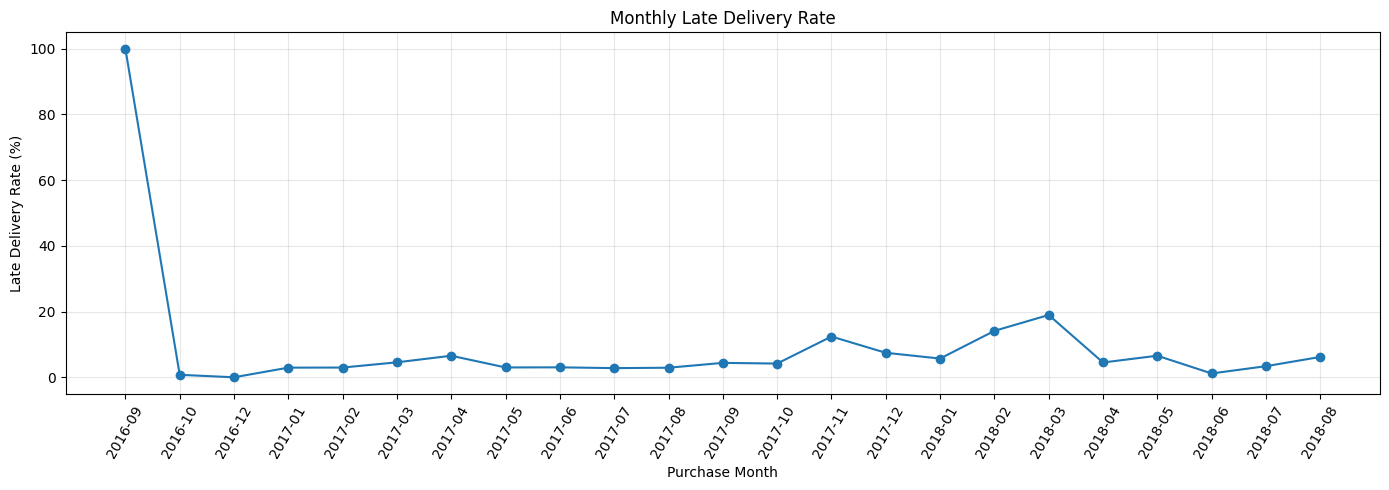

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_performance["purchase_month"],
    monthly_performance["late_rate_pct"],
    marker="o"
)

plt.title("Monthly Late Delivery Rate")
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:


# Step 12: Check monthly order volumes

display(
    monthly_performance[
        [
            "purchase_month",
            "total_orders",
            "late_orders",
            "late_rate_pct"
        ]
    ].round(2)
)


,purchase_month,total_orders,late_orders,late_rate_pct
0,2016-09,1,1,100.00
1,2016-10,265,2,0.75
2,2016-12,1,0,0.00
3,2017-01,750,22,2.93
4,2017-02,1653,49,2.96
5,2017-03,2546,116,4.56
6,2017-04,2303,151,6.56
7,2017-05,3545,106,2.99
8,2017-06,3135,95,3.03
9,2017-07,3872,108,2.79


In [16]:

# Step 13: Rank months by late delivery rate

reliable_months = monthly_performance[
    monthly_performance["total_orders"] >= 100
].copy()

worst_months = reliable_months.sort_values(
    by="late_rate_pct",
    ascending=False
)

print("TOP 5 MONTHS WITH THE HIGHEST LATE DELIVERY RATES")

display(
    worst_months[
        [
            "purchase_month",
            "total_orders",
            "late_orders",
            "late_rate_pct",
            "avg_delivery_days"
        ]
    ].head(5).round(2)
)


TOP 5 MONTHS WITH THE HIGHEST LATE DELIVERY RATES


,purchase_month,total_orders,late_orders,late_rate_pct,avg_delivery_days
17,2018-03,7003,1328,18.96,16.30
16,2018-02,6555,926,14.13,16.95
13,2017-11,7288,904,12.40,15.16
14,2017-12,5513,411,7.46,15.39
19,2018-05,6749,443,6.56,11.42


In [17]:

# Load customer data
customers = pd.read_csv(
    "/content/olist_data/olist_customers_dataset.csv"
)

# Check customer location columns
print(customers.columns.tolist())

display(customers.head())


['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [18]:

# Add customer state to each delivered order
delivered_geo = delivered.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Rows in geographical dataset:", len(delivered_geo))
print("Missing customer states:", delivered_geo["customer_state"].isna().sum())

display(
    delivered_geo[
        ["order_id", "customer_state", "delivery_delay_days"]
    ].head()
)


Rows in geographical dataset: 96470
Missing customer states: 0


,order_id,customer_state,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,SP,-8
1,53cdb2fc8bc7dce0b6741e2150273451,BA,-6
2,47770eb9100c2d0c44946d9cf07ec65d,GO,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,-10


In [19]:

# Step 15: State-wise delivery performance

state_performance = (
    delivered_geo.groupby("customer_state")
    .agg(
        total_orders=("order_id", "count"),
        late_orders=(
            "delivery_delay_days",
            lambda x: (x > 0).sum()
        ),
        avg_delivery_days=("actual_delivery_days", "mean")
    )
    .reset_index()
)

# Calculate late delivery percentage
state_performance["late_rate_pct"] = (
    state_performance["late_orders"]
    / state_performance["total_orders"] * 100
)

# Show states with at least 100 delivered orders
state_performance = state_performance[
    state_performance["total_orders"] >= 100
]

# Rank states by highest late delivery rate
state_performance = state_performance.sort_values(
    "late_rate_pct",
    ascending=False
)

print("TOP 10 STATES WITH HIGHEST LATE DELIVERY RATES")

display(
    state_performance.head(10).round(2)
)


TOP 10 STATES WITH HIGHEST LATE DELIVERY RATES


,customer_state,total_orders,late_orders,avg_delivery_days,late_rate_pct
1,AL,397,85,24.54,21.41
9,MA,717,125,21.57,17.43
24,SE,335,51,21.52,15.22
16,PI,476,66,19.46,13.87
5,CE,1279,176,21.27,13.76
4,BA,3256,396,19.34,12.16
18,RJ,12350,1495,15.31,12.11
13,PA,946,106,23.77,11.21
7,ES,1995,214,15.79,10.73
14,PB,517,54,20.43,10.44


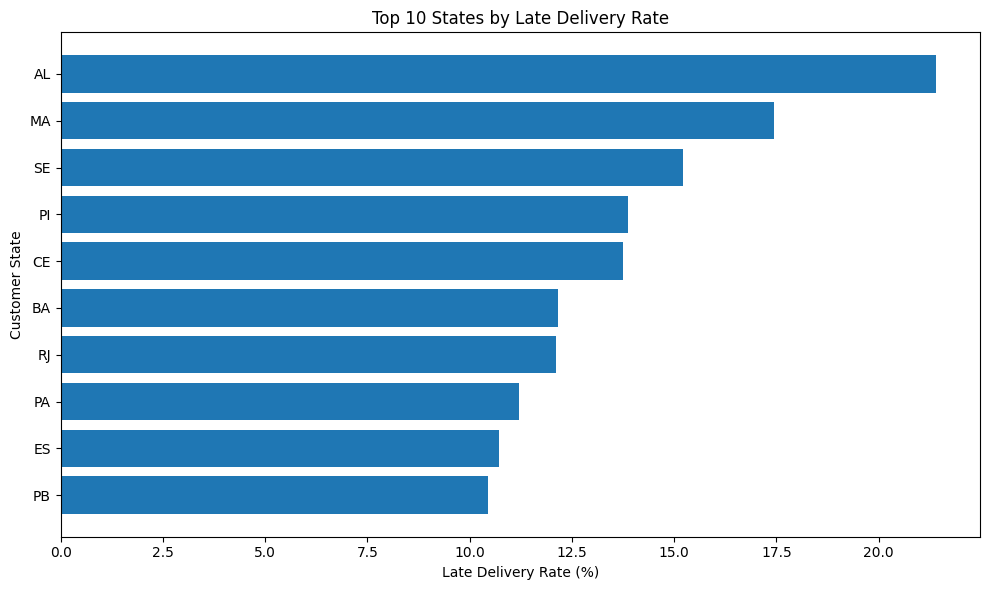

In [20]:

import matplotlib.pyplot as plt

# Sort the states from highest to lowest late rate
chart_data = state_performance.head(10).sort_values(
    "late_rate_pct",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    chart_data["customer_state"],
    chart_data["late_rate_pct"]
)

plt.title("Top 10 States by Late Delivery Rate")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Customer State")
plt.tight_layout()
plt.show()


In [21]:

# Step 17: Load customer reviews

reviews = pd.read_csv(
    "/content/olist_data/olist_order_reviews_dataset.csv"
)

print("Reviews dataset shape:", reviews.shape)

display(reviews.head())


Reviews dataset shape: (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [22]:

# Keep the order ID and delivery performance
delivery_reviews = delivered[
    ["order_id", "delivery_delay_days", "delivery_performance"]
].merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="left",
    validate="one_to_many"
)

print("Merged records:", len(delivery_reviews))
print("Missing review scores:", delivery_reviews["review_score"].isna().sum())

display(delivery_reviews.head())


Merged records: 96999
Missing review scores: 646


,order_id,delivery_delay_days,delivery_performance,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,-8,On Time,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,-6,On Time,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,-18,On Time,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,-13,On Time,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,-10,On Time,5.0


In [23]:

# Step 18: Create one review score per order

reviews_clean = (
    reviews.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

# Merge the cleaned reviews with delivery data
delivery_reviews_clean = delivered[
    ["order_id", "delivery_delay_days", "delivery_performance"]
].merge(
    reviews_clean,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Delivered orders:", len(delivered))
print("Merged orders:", len(delivery_reviews_clean))
print("Missing review scores:",
      delivery_reviews_clean["review_score"].isna().sum())

display(delivery_reviews_clean.head())


Delivered orders: 96470
Merged orders: 96470
Missing review scores: 646


,order_id,delivery_delay_days,delivery_performance,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,-8,On Time,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,-6,On Time,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,-18,On Time,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,-13,On Time,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,-10,On Time,5.0


In [24]:

# Compare average review scores by delivery performance

review_comparison = (
    delivery_reviews_clean
    .dropna(subset=["review_score"])
    .groupby("delivery_performance")
    .agg(
        orders_with_reviews=("order_id", "count"),
        average_review_score=("review_score", "mean")
    )
    .reset_index()
)

display(review_comparison.round(2))


,delivery_performance,orders_with_reviews,average_review_score
0,Late,6381,2.27
1,On Time,89443,4.29


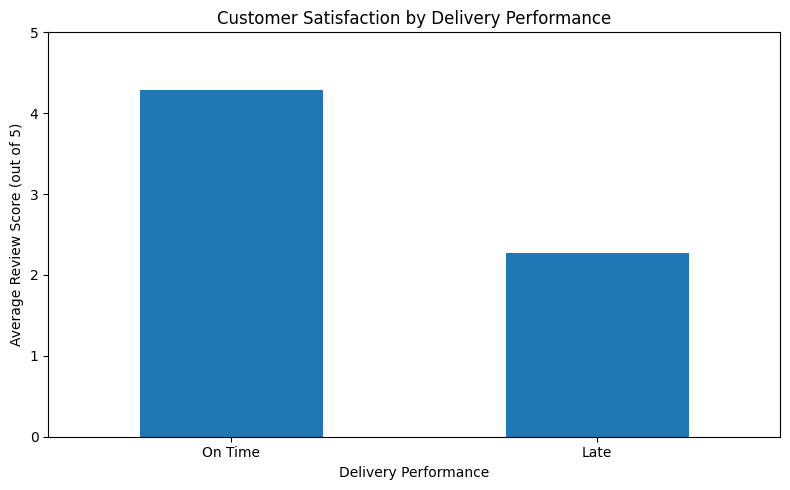

In [25]:

import matplotlib.pyplot as plt

# Prepare chart data
review_chart = review_comparison.set_index(
    "delivery_performance"
)["average_review_score"]

# Create bar chart
plt.figure(figsize=(8, 5))

review_chart.reindex(["On Time", "Late"]).plot(
    kind="bar"
)

plt.title("Customer Satisfaction by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [26]:

# Step 21: Prepare the final analysis dataset

final_data = delivered_geo[
    [
        "order_id",
        "customer_id",
        "customer_state",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "actual_delivery_days",
        "delivery_delay_days",
        "delivery_performance",
        "purchase_month"
    ]
].copy() if "purchase_month" in delivered_geo.columns else delivered_geo[
    [
        "order_id",
        "customer_id",
        "customer_state",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "actual_delivery_days",
        "delivery_delay_days",
        "delivery_performance"
    ]
].copy()

# Add purchase month if it is not already present
if "purchase_month" not in final_data.columns:
    final_data["purchase_month"] = (
        final_data["order_purchase_timestamp"]
        .dt.to_period("M")
        .astype(str)
    )

# Add review score, one row per order
final_data = final_data.merge(
    reviews_clean,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Final dataset shape:", final_data.shape)
print("Duplicate order IDs:", final_data["order_id"].duplicated().sum())

display(final_data.head())


Final dataset shape: (96470, 12)
Duplicate order IDs: 0


,order_id,customer_id,customer_state,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,delivery_delay_days,delivery_performance,purchase_month,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,SP,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,8.436574,-8,On Time,2017-10,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,BA,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,13.782037,-6,On Time,2018-07,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,GO,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,9.394213,-18,On Time,2018-08,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,RN,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,13.208750,-13,On Time,2017-11,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,SP,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,2.873877,-10,On Time,2018-02,5.0


In [27]:

# Save the final dataset
output_file = "/content/operations_analytics_final.csv"

final_data.to_csv(output_file, index=False)

print("Dataset saved successfully:", output_file)


Dataset saved successfully: /content/operations_analytics_final.csv


In [28]:

from google.colab import files

files.download("/content/operations_analytics_final.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:

# Validate the final dataset

print("Dataset shape:", final_data.shape)
print("Duplicate order IDs:", final_data["order_id"].duplicated().sum())
print("Review score column exists:", "review_score" in final_data.columns)

print("\nMissing values:")
print(final_data[[
    "customer_state",
    "delivery_delay_days",
    "review_score"
]].isnull().sum())

display(final_data.head())


Dataset shape: (96470, 12)
Duplicate order IDs: 0
Review score column exists: True

Missing values:
customer_state           0
delivery_delay_days      0
review_score           646
dtype: int64


,order_id,customer_id,customer_state,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,delivery_delay_days,delivery_performance,purchase_month,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,SP,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,8.436574,-8,On Time,2017-10,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,BA,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,13.782037,-6,On Time,2018-07,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,GO,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,9.394213,-18,On Time,2018-08,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,RN,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,13.208750,-13,On Time,2017-11,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,SP,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,2.873877,-10,On Time,2018-02,5.0
